# Notebook 1 — K-means clustering with scikit-learn

**Lecture roadmap**

1. **K-means** (this notebook): group snapshots into $K$ clusters.
2. **Cluster-based Network Modeling (CNM)**: use the clusters as nodes of a network to model the dynamics from data.
3. **Quantized local ROM (ql-ROM)**: use the clusters to build local reduced-order models from the equations.

In this notebook we use the ready-made `KMeans` class of scikit-learn. K-means groups the data into $K$ clusters; each cluster is represented by its **centroid** (the mean of its points), and each point belongs to the cluster with the nearest centroid.

Requirements: `numpy`, `scipy`, `scikit-learn`, `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

## 1. A simple dataset

data shape: (1500, 2)


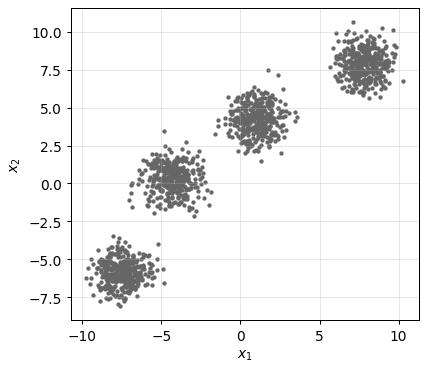

In [2]:
X, _ = make_blobs(n_samples=1500, centers=4, cluster_std=0.9, random_state=3)
print("data shape:", X.shape)

plt.figure(figsize=(5, 4.5))
plt.scatter(X[:, 0], X[:, 1], s=6, c="0.4")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.show()

## 2. Fitting K-means

The main parameters of `KMeans` are:

- `n_clusters`: the number of clusters $K$;
- `n_init`: how many times the algorithm is run from different initial centroids (the best run is kept);
- `random_state`: the seed, for reproducible results.

After `fit`, the object contains the results:

| attribute | meaning |
|---|---|
| `cluster_centers_` | the $K$ centroids |
| `labels_` | the cluster index of each point |
| `inertia_` | sum of the squared distances of the points from their centroid |
| `n_iter_` | number of iterations of the best run |

centroids:
 [[-4.322  0.278]
 [ 7.817  7.882]
 [-7.487 -5.867]
 [ 0.99   4.219]]
first 10 labels: [3 1 1 3 0 0 0 0 0 2]
points per cluster: [375 375 375 375]
inertia = 2385.4,  iterations = 2


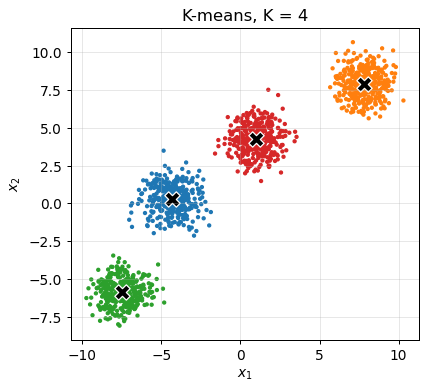

In [3]:
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)

print("centroids:\n", np.round(km.cluster_centers_, 3))
print("first 10 labels:", km.labels_[:10])
print("points per cluster:", np.bincount(km.labels_))
print(f"inertia = {km.inertia_:.1f},  iterations = {km.n_iter_}")

plt.figure(figsize=(5, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="tab10", vmin=0, vmax=9, s=6)
plt.scatter(*km.cluster_centers_.T, c="k", marker="X", s=150, edgecolor="w")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title("K-means, K = 4")
plt.show()

## 3. Assigning new points

`predict` assigns new points to the nearest centroid; `transform` returns the distances from all centroids. Applying `predict` to a fine grid shows the region of the plane that belongs to each cluster (the *Voronoi cells* of the centroids).

clusters of the new points: [0 1 2]
distances from the centroids:
 [[ 4.33 11.1   9.51  4.33]
 [10.45  4.03 16.55  4.09]
 [ 4.6  18.22  2.39 10.79]]


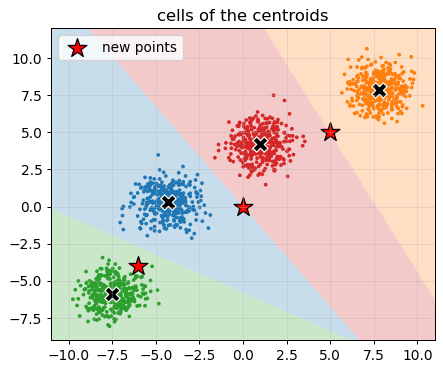

In [4]:
new_points = np.array([[0.0, 0.0], [5.0, 5.0], [-6.0, -4.0]])
print("clusters of the new points:", km.predict(new_points))
print("distances from the centroids:\n", np.round(km.transform(new_points), 2))

gx, gy = np.meshgrid(np.linspace(-11, 11, 300), np.linspace(-9, 12, 300))
regions = km.predict(np.column_stack([gx.ravel(), gy.ravel()])).reshape(gx.shape)

plt.figure(figsize=(5.5, 4.5))
plt.imshow(regions, origin="lower", extent=[-11, 11, -9, 12], cmap="tab10", vmin=0, vmax=9, alpha=0.25, aspect="auto")
plt.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="tab10", vmin=0, vmax=9, s=4)
plt.scatter(*km.cluster_centers_.T, c="k", marker="X", s=150, edgecolor="w")
plt.scatter(*new_points.T, c="r", marker="*", s=250, edgecolor="k", label="new points")
plt.legend(loc="upper left"); plt.title("cells of the centroids")
plt.show()

## 4. Choosing the number of clusters

Three common criteria:

- **elbow**: plot `inertia_` against $K$ and look for the point where the curve stops decreasing quickly;
- **silhouette score** (`sklearn.metrics.silhouette_score`): between $-1$ and $1$, higher is better;
- **BIC** (*Bayesian information criterion*): it balances the quality of the fit against the number of clusters; lower is better. It is the criterion used in the ql-ROM paper (Colanera & Magri, 2025) to choose $K$.

**General form.** For a probabilistic model with $n_p$ parameters fitted to $M$ data points $\boldsymbol{x}_m$,

$$\mathrm{BIC} = n_p \log M - 2\ell, \qquad \ell = \sum_{m=1}^{M} \log P(\boldsymbol{x}_m),$$

where $\ell$ is the log-likelihood of the data. The first term penalizes complexity, the second rewards a good fit.

**K-means.** K-means corresponds to modeling each cluster as a Gaussian centered at its centroid $\boldsymbol{c}_k$, with the same variance $\sigma^2$ in every direction and for every cluster. A point of cluster $k$ has probability

$$P(\boldsymbol{x}_m) = \frac{n_k}{M}\,\mathcal{N}\big(\boldsymbol{x}_m;\,\boldsymbol{c}_k,\,\sigma^2\boldsymbol{I}\big), \qquad \sigma^2 = \frac{J}{d}, \qquad J = \frac{1}{M}\sum_{m=1}^{M}\|\boldsymbol{x}_m - \boldsymbol{c}_{k(m)}\|^2,$$

where $n_k$ is the number of points in cluster $k$, $d$ the dimension of the data and $J$ = `inertia_` / $M$. The parameters are the centroids, $n_p = K d$. Substituting into the general form, dropping the terms that do not depend on $K$ and dividing by $d$ gives

$$\mathrm{BIC} = M\log J + K\log M - \frac{2}{d}\sum_{k=1}^{K} n_k \log\frac{n_k}{M}.$$


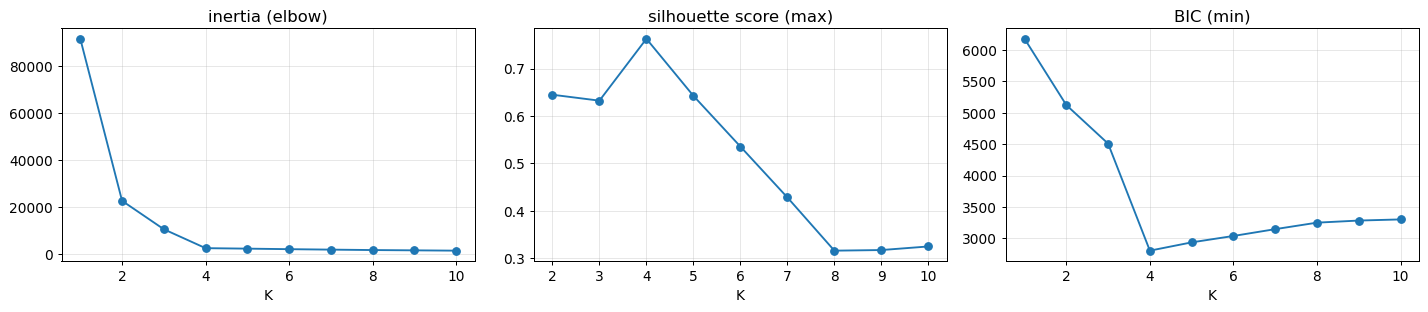

K with the highest silhouette: 4 | K with the lowest BIC: 4


In [5]:
def bic_kmeans(X, km):
    # BIC of a fitted KMeans object (ql-ROM paper, eq. 18)
    M, d = X.shape
    J = km.inertia_ / M
    nk = np.bincount(km.labels_)
    nk = nk[nk > 0]
    return M * np.log(J) + len(nk) * np.log(M) - 2.0 / d * np.sum(nk * np.log(nk / M))

Ks = range(1, 11)
inertia, silhouette, bic = [], [], []
for K in Ks:
    km_K = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
    inertia.append(km_K.inertia_)
    silhouette.append(silhouette_score(X, km_K.labels_) if K > 1 else np.nan)
    bic.append(bic_kmeans(X, km_K))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].plot(Ks, inertia, "o-"); ax[0].set_title("inertia (elbow)")
ax[1].plot(Ks, silhouette, "o-"); ax[1].set_title("silhouette score (max)")
ax[2].plot(Ks, bic, "o-"); ax[2].set_title("BIC (min)")
for a in ax:
    a.set_xlabel("K")
plt.tight_layout(); plt.show()
print("K with the highest silhouette:", list(Ks)[int(np.nanargmax(silhouette))],
      "| K with the lowest BIC:", list(Ks)[int(np.argmin(bic))])

## 5. K-means on a trajectory of a dynamical system

In the next two notebooks the data are **snapshots**: states of a dynamical system sampled in time. We use the Lorenz system

$$\dot x = \sigma(y-x), \qquad \dot y = x(\rho - z) - y, \qquad \dot z = xy - bz,$$

with $\sigma = 10$, $\rho = 28$, $b = 8/3$. Each snapshot is a point $(x, y, z)$.

Lorenz snapshots: (50000, 3)


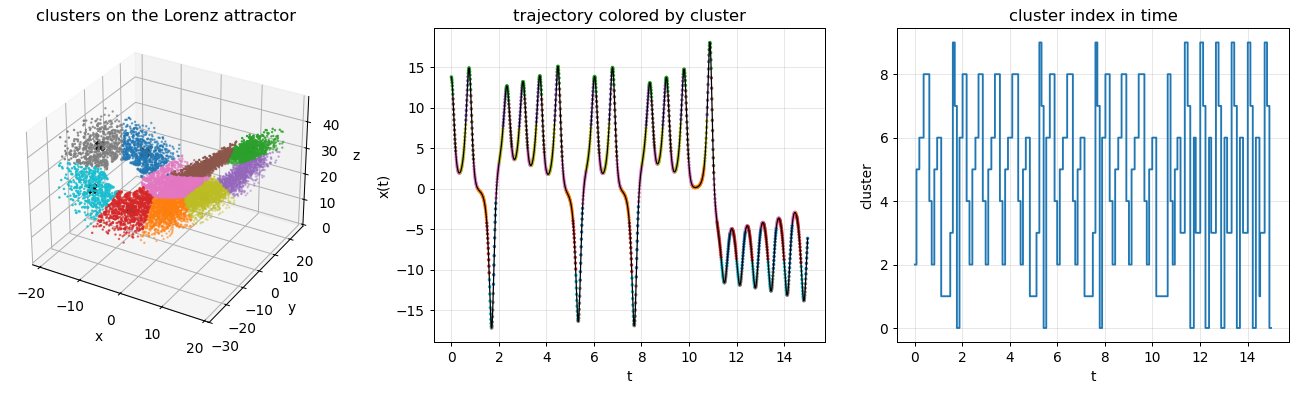

In [6]:
def lorenz(t, s, sigma=10.0, rho=28.0, b=8.0 / 3.0):
    x, y, z = s
    return [sigma * (y - x), x * (rho - z) - y, x * y - b * z]

dt = 0.01
sol = solve_ivp(lorenz, [0, 520], [1.0, 1.0, 1.0], t_eval=np.arange(0, 520, dt), rtol=1e-9, atol=1e-9)
XL = sol.y.T[int(20 / dt):]          # discard the initial transient
tL = np.arange(len(XL)) * dt
print("Lorenz snapshots:", XL.shape)

kmL = KMeans(n_clusters=10, n_init=10, random_state=0).fit(XL)
labL = kmL.labels_

fig = plt.figure(figsize=(15, 4.5))
ax = fig.add_subplot(131, projection="3d")
ax.scatter(*XL[::5].T, c=labL[::5], cmap="tab10", s=1)
ax.scatter(*kmL.cluster_centers_.T, c="k", s=60, marker="X")
ax.set_title("clusters on the Lorenz attractor"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax = fig.add_subplot(132)
sl = slice(0, int(15 / dt))
ax.plot(tL[sl], XL[sl, 0], "k", lw=1)
ax.scatter(tL[sl], XL[sl, 0], c=labL[sl], cmap="tab10", s=3)
ax.set_xlabel("t"); ax.set_ylabel("x(t)"); ax.set_title("trajectory colored by cluster")
ax = fig.add_subplot(133)
ax.step(tL[sl], labL[sl], where="post")
ax.set_xlabel("t"); ax.set_ylabel("cluster"); ax.set_title("cluster index in time")
plt.tight_layout(); plt.show()

Why $K = 10$? For data that do not form separate groups, like the points of an attractor, the BIC usually has no minimum: it keeps decreasing as $K$ grows. As in the ql-ROM paper, we then look at its variation $\Delta\mathrm{BIC}/\Delta K$ and choose the $K$ after which adding clusters brings little improvement (elbow).

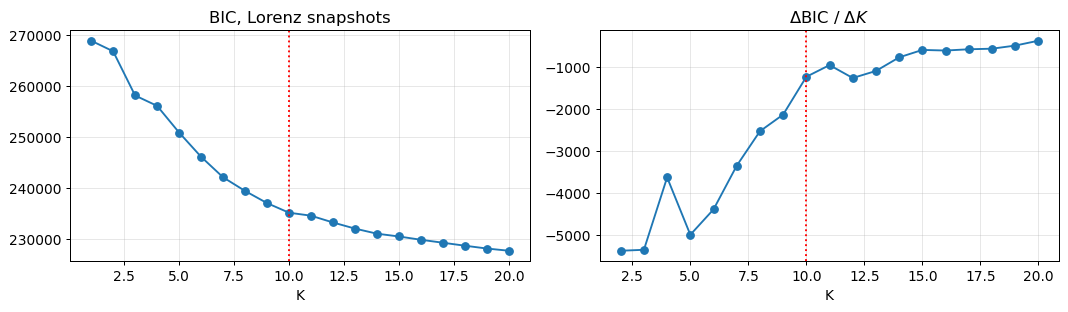

In [10]:
Ks_L = np.arange(1, 21)
bic_L = np.array([bic_kmeans(XL, KMeans(n_clusters=K, n_init=10, random_state=0).fit(XL)) for K in Ks_L])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(Ks_L, bic_L, "o-"); ax[0].set_title("BIC, Lorenz snapshots")
dbic_L = np.gradient(bic_L, Ks_L, edge_order=2)
ax[1].plot(Ks_L[1:], dbic_L[1:], "o-"); ax[1].set_title(r"$\Delta$BIC / $\Delta K$")
for a in ax:
    a.set_xlabel("K"); a.axvline(10, color="r", ls=":")
plt.tight_layout(); plt.show()

The variation of the BIC becomes much smaller after $K \approx 10$: this is the value we use in the next two notebooks. The elbow is not sharp, so other nearby values are also reasonable; in Notebook 3 we will check how the results depend on $K$.

The cluster index in time turns the trajectory into a **sequence of symbols**. Counting the jumps between clusters shows that from each cluster the trajectory can only move to a few others: this network of transitions is the starting point of **Notebook 2 (CNM)**. In **Notebook 3 (ql-ROM)** we will instead build a reduced-order model of the equations inside each cluster.

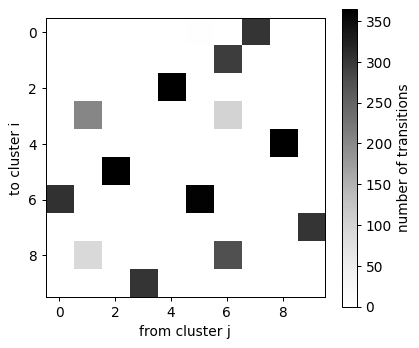

3638 transitions, 15 distinct pairs (i, j) out of 90 possible


In [8]:
jumps = np.where(np.diff(labL) != 0)[0]
counts = np.zeros((10, 10), int)
np.add.at(counts, (labL[jumps + 1], labL[jumps]), 1)      # counts[i, j] = number of jumps j -> i

plt.figure(figsize=(5, 4.3))
plt.imshow(counts, cmap="Greys")
plt.colorbar(label="number of transitions")
plt.xlabel("from cluster j"); plt.ylabel("to cluster i"); plt.grid(False)
plt.show()
print(f"{len(jumps)} transitions, {np.count_nonzero(counts)} distinct pairs (i, j) out of {10 * 9} possible")